# Random Forest

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay, roc_curve)

In [ ]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
chronic_kidney_disease = fetch_ucirepo(id=336) 
  
# data (as pandas dataframes) 
X = chronic_kidney_disease.data.features 
y = chronic_kidney_disease.data.targets 

# Cleaning and Loading Data

In [ ]:
ckd = fetch_ucirepo(id=336)
df = pd.concat([ckd.data.features, ckd.data.targets], axis=1)
 
str_cols = df.select_dtypes(exclude='number').columns.tolist()
for c in str_cols:
    df[c] = df[c].str.strip().replace({'?': np.nan, '': np.nan})
 
ordinal_cols = ['sg', 'al', 'su']
num_cols = ['age', 'bp', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
cat_cols = ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']
 
# likely data-entry errors -> NaN
df.loc[df['sod'] < 100, 'sod'] = np.nan
df.loc[df['pot'] > 10, 'pot'] = np.nan
 
# encode target (do NOT keep n_missing as a feature)
y = (df['class'] == 'ckd').astype(int)
X = df[num_cols + ordinal_cols + cat_cols].copy()
X[cat_cols] = X[cat_cols].astype(object)

# Stratified Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Pipeline

In [ ]:
def build_pipeline(numeric, ordinal, categorical, add_indicator=False, **rf_kwargs):
    num_pipe = SimpleImputer(strategy='median', add_indicator=add_indicator)
    ord_pipe = SimpleImputer(strategy='most_frequent', add_indicator=add_indicator)
    cat_pipe = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent', add_indicator=add_indicator)),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ])
    pre = ColumnTransformer([
        ('num', num_pipe, numeric),
        ('ord', ord_pipe, ordinal),
        ('cat', cat_pipe, categorical),
    ])
    rf = RandomForestClassifier(
        n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1, **rf_kwargs
    )
    return Pipeline([('pre', pre), ('model', rf)])

# Cross Validation Testing on Training Data

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['roc_auc', 'recall', 'precision', 'f1']
 
reduced_num = [c for c in num_cols if c not in ('rbcc', 'wbcc')]
reduced_cat = [c for c in cat_cols if c != 'rbc']
 
experiments = {
    'RF, no missing flags':        build_pipeline(num_cols, ordinal_cols, cat_cols, add_indicator=False),
    'RF, with missing flags':      build_pipeline(num_cols, ordinal_cols, cat_cols, add_indicator=True),
    'RF, drop rbc/rbcc/wbcc':      build_pipeline(reduced_num, ordinal_cols, reduced_cat, add_indicator=False),
}
 
rows = {}
for name, pipe in experiments.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {m: res[f'test_{m}'].mean() for m in scoring}
    rows[name].update({f'{m}_std': res[f'test_{m}'].std() for m in scoring})
 
cv_results = pd.DataFrame(rows).T.round(3)
print('\n=== 5-fold CV results (train set) ===')
print(cv_results[scoring])
print('\nStd devs:')
print(cv_results[[f'{m}_std' for m in scoring]])


=== 5-fold CV results (train set) ===
                        roc_auc  recall  precision     f1
RF, no missing flags        1.0   1.000       0.99  0.995
RF, with missing flags      1.0   1.000       0.99  0.995
RF, drop rbc/rbcc/wbcc      1.0   0.995       0.99  0.993

Std devs:
                        roc_auc_std  recall_std  precision_std  f1_std
RF, no missing flags            0.0        0.00          0.012   0.006
RF, with missing flags          0.0        0.00          0.012   0.006
RF, drop rbc/rbcc/wbcc          0.0        0.01          0.012   0.010


# Choosing RF, No Missing Flags to Train


=== Test set results (RF, no missing flags) ===
              precision    recall  f1-score   support

      notckd       1.00      1.00      1.00        30
         ckd       1.00      1.00      1.00        50

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

ROC-AUC: 1.0
Confusion matrix:
 [[30  0]
 [ 0 50]]


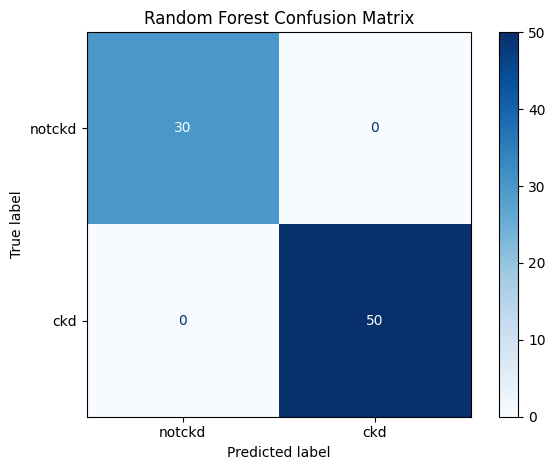

In [ ]:
final_name = 'RF, no missing flags'  
final_model = experiments[final_name]
final_model.fit(X_train, y_train)
 
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]
 
print(f'\n=== Test set results ({final_name}) ===')
print(classification_report(y_test, y_pred, target_names=['notckd', 'ckd']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_proba), 3))
print('Confusion matrix:\n', confusion_matrix(y_test, y_pred))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['notckd', 'ckd']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Random Forest Confusion Matrix')
plt.tight_layout()
plt.show()


Top 15 features:
num__hemo         0.198
num__pcv          0.150
num__sc           0.123
ord__sg           0.111
num__rbcc         0.084
ord__al           0.059
cat__htn_no       0.050
cat__htn_yes      0.036
cat__dm_no        0.026
cat__dm_yes       0.025
num__bu           0.023
num__bgr          0.023
num__sod          0.017
cat__pc_normal    0.010
num__bp           0.010
dtype: float64


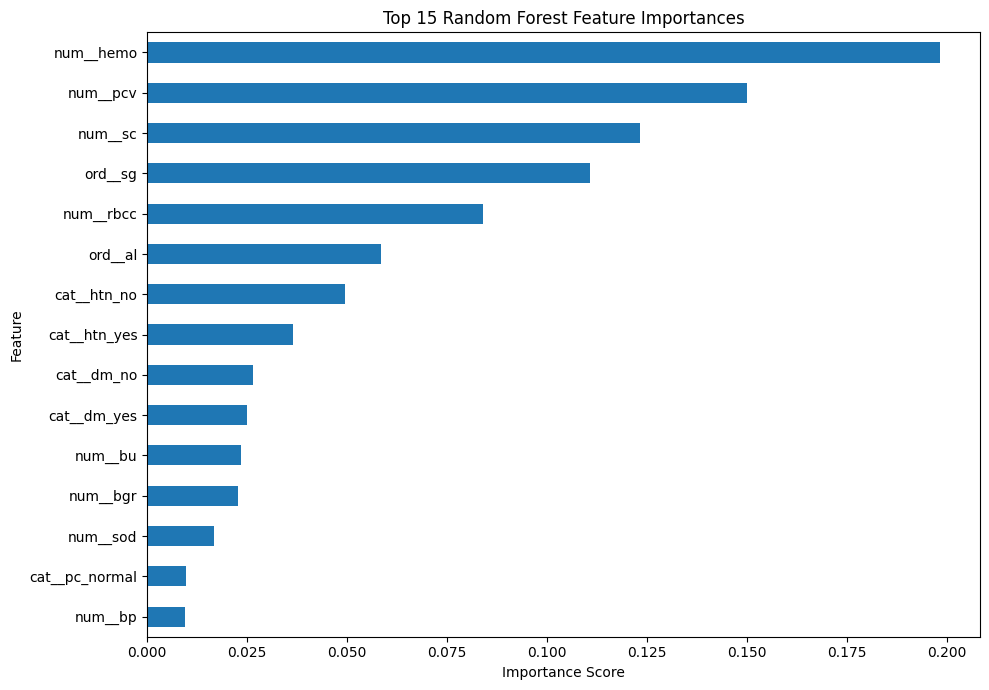

In [ ]:
names = final_model.named_steps['pre'].get_feature_names_out()
importances = pd.Series(
    final_model.named_steps['model'].feature_importances_, index=names
).sort_values(ascending=False)
 
print('\nTop 15 features:')
print(importances.head(15).round(3))

# Top 15 Feature Importances
top_features = importances.head(15).sort_values()

plt.figure(figsize=(10, 7))
top_features.plot(kind='barh')

plt.title('Top 15 Random Forest Feature Importances')
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

# ROC Curve

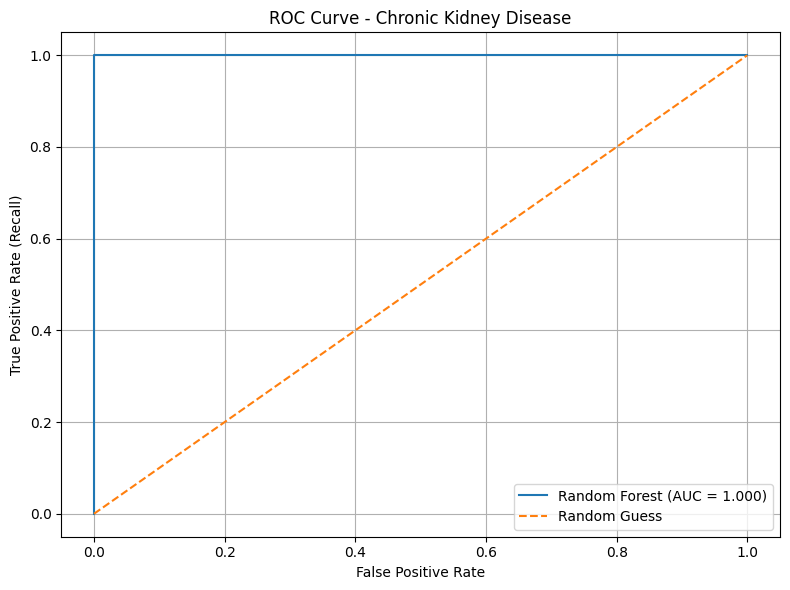

In [ ]:
# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.title('ROC Curve - Chronic Kidney Disease')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()